# Genuine Multipartite Entanglement — Interactive Analysis

This notebook demonstrates the `hubbard_gme` package:
1. Build and diagonalise the Hubbard Hamiltonian
2. Compute n-body RDMs
3. Run GME analysis
4. Visualise results inline

In [1]:
import sys, os
sys.path.insert(0, os.path.join('..', 'src'))

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from hubbard_gme.hamiltonian import compute_ground_and_excited_states
from hubbard_gme.rdm import compute_all_pure_rdms, generate_site_clusters
from hubbard_gme.metrics import rdm_metrics, short_metrics_report
from hubbard_gme.gme import check_GME_for_all_rdms, compute_C_GME_pure, Cgme_lower_bound
from hubbard_gme.visualization import plot_rdm_heatmap
from hubbard_gme.pipeline import run_pure_analysis

print('hubbard_gme loaded successfully')

hubbard_gme loaded successfully


## 1  System parameters

In [38]:
L    = 6       # number of sites
t    = 1.0     # hopping
U    = 4.0     # on-site repulsion
Ne   = L       # half-filling
mode = 'uniform'

## 2  Exact diagonalisation

In [39]:
E0, psi0, E1, psi1, n_so = compute_ground_and_excited_states(
    L=L, t=t, U=U, mode=mode, n_electrons=Ne
)
print(f'E0 = {E0:.8f}')
print(f'E1 = {E1:.8f}')
print(f'Gap = {E1-E0:.6f}')

E0 = -3.66870618
E1 = -2.89838147
Gap = 0.770325


## 3  Compute n-body RDMs

In [40]:
rdm_pure, rdm_ex, metrics = compute_all_pure_rdms(
    L=L, psi0=psi0, psi1=psi1,
    n_spin_orbitals=n_so, n_electrons=Ne,
    max_n=5
)
print(f'Total RDMs computed: {len(rdm_pure)}')

  Computing 1-body RDMs (6 clusters) …
  Computing 2-body RDMs (6 clusters) …
  Computing 3-body RDMs (6 clusters) …
  Computing 4-body RDMs (6 clusters) …
  Computing 5-body RDMs (6 clusters) …
Total RDMs computed: 30


In [64]:
import numpy as np
from itertools import combinations
from collections import defaultdict

def compare_all_subsystem_rdms_pretty(
    rdm_dict,
    atol=1e-10,
    rtol=1e-10,
    show_equal=True,
    show_not_equal=True,
):
    equal_pairs = defaultdict(list)
    not_equal_pairs = defaultdict(list)

    keys = sorted(rdm_dict.keys(), key=lambda x: (len(x), x))

    total_compared = 0

    for k1, k2 in combinations(keys, 2):
        rho1 = rdm_dict[k1]
        rho2 = rdm_dict[k2]

        if rho1.shape != rho2.shape:
            continue

        size = len(k1)
        total_compared += 1

        max_diff = float(np.max(np.abs(rho1 - rho2)))
        same = np.allclose(rho1, rho2, atol=atol, rtol=rtol)

        row = (k1, k2, rho1.shape, max_diff)

        if same:
            equal_pairs[size].append(row)
        else:
            not_equal_pairs[size].append(row)

    total_equal = sum(len(v) for v in equal_pairs.values())
    total_not_equal = sum(len(v) for v in not_equal_pairs.values())

    print("\n" + "=" * 90)
    print("RDM COMPARISON SUMMARY")
    print("=" * 90)
    print(f"Total comparable pairs : {total_compared}")
    print(f"Equal pairs            : {total_equal}")
    print(f"Not equal pairs        : {total_not_equal}")
    print("=" * 90)

    def print_table(title, data, symbol):
        print("\n" + title)
        print("=" * 90)

        if not data:
            print("None")
            return

        for size in sorted(data.keys()):
            print(f"\nSubsystem size = {size}")
            print("-" * 90)
            print(f"{'Status':<8} {'RDM 1':<22} {'RDM 2':<22} {'Shape':<15} {'Max diff'}")
            print("-" * 90)

            for k1, k2, shape, max_diff in sorted(data[size], key=lambda x: (x[0], x[1])):
                print(
                    f"{symbol:<8} "
                    f"{str(k1):<22} "
                    f"{str(k2):<22} "
                    f"{str(shape):<15} "
                    f"{max_diff:.3e}"
                )

    if show_equal:
        print_table("EQUAL RDM PAIRS", equal_pairs, "EQUAL")

    if show_not_equal:
        print_table("NOT EQUAL RDM PAIRS", not_equal_pairs, "DIFF")

    return {
        "equal": dict(equal_pairs),
        "not_equal": dict(not_equal_pairs),
        "summary": {
            "total_compared": total_compared,
            "total_equal": total_equal,
            "total_not_equal": total_not_equal,
        },
    }
results = compare_all_subsystem_rdms_not_equal(rdm_pure)
print(results)


RDM COMPARISON: ONLY NON-EQUAL SUBSYSTEMS

Total compared pairs : 75
Non-equal pairs      : 0
All comparable RDMs are equal within tolerance.
{((0,), (1,)): {'same': True, 'max_diff': np.float64(3.3306690738754696e-16), 'shape': (2, 2)}, ((0,), (2,)): {'same': True, 'max_diff': np.float64(1.1102230246251565e-16), 'shape': (2, 2)}, ((0,), (3,)): {'same': True, 'max_diff': np.float64(4.440892098500626e-16), 'shape': (2, 2)}, ((0,), (4,)): {'same': True, 'max_diff': np.float64(1.1102230246251565e-16), 'shape': (2, 2)}, ((0,), (5,)): {'same': True, 'max_diff': np.float64(4.440892098500626e-16), 'shape': (2, 2)}, ((1,), (2,)): {'same': True, 'max_diff': np.float64(2.7755575615628914e-16), 'shape': (2, 2)}, ((1,), (3,)): {'same': True, 'max_diff': np.float64(1.1102230246251565e-16), 'shape': (2, 2)}, ((1,), (4,)): {'same': True, 'max_diff': np.float64(3.3306690738754696e-16), 'shape': (2, 2)}, ((1,), (5,)): {'same': True, 'max_diff': np.float64(1.1102230246251565e-16), 'shape': (2, 2)}, ((2

In [65]:
from collections import defaultdict

def print_rdm_results(results, show_equal=True, show_not_equal=True):
    equal = defaultdict(list)
    not_equal = defaultdict(list)

    for (k1, k2), info in results.items():
        size = len(k1)
        row = {
            "rdm1": k1,
            "rdm2": k2,
            "shape": info["shape"],
            "max_diff": float(info["max_diff"]),
            "same": info["same"],
        }

        if info["same"]:
            equal[size].append(row)
        else:
            not_equal[size].append(row)

    total_equal = sum(len(v) for v in equal.values())
    total_not_equal = sum(len(v) for v in not_equal.values())
    total = total_equal + total_not_equal

    print("\n" + "=" * 90)
    print("RDM COMPARISON RESULTS")
    print("=" * 90)
    print(f"Total comparable pairs : {total}")
    print(f"Equal pairs            : {total_equal}")
    print(f"Not equal pairs        : {total_not_equal}")
    print("=" * 90)

    def print_section(title, data, status):
        print("\n" + title)
        print("=" * 90)

        if not data:
            print("None")
            return

        for size in sorted(data.keys()):
            rows = sorted(data[size], key=lambda x: (x["rdm1"], x["rdm2"]))

            print(f"\nSubsystem size = {size}")
            print("-" * 90)
            print(f"{'Status':<10} {'RDM 1':<22} {'RDM 2':<22} {'Shape':<12} {'Max diff'}")
            print("-" * 90)

            for row in rows:
                print(
                    f"{status:<10} "
                    f"{str(row['rdm1']):<22} "
                    f"{str(row['rdm2']):<22} "
                    f"{str(row['shape']):<12} "
                    f"{row['max_diff']:.3e}"
                )

    if show_equal:
        print_section("EQUAL SUBSYSTEM RDMs", equal, "EQUAL")

    if show_not_equal:
        print_section("NOT-EQUAL SUBSYSTEM RDMs", not_equal, "DIFF")

print_rdm_results(results)


RDM COMPARISON RESULTS
Total comparable pairs : 75
Equal pairs            : 75
Not equal pairs        : 0

EQUAL SUBSYSTEM RDMs

Subsystem size = 1
------------------------------------------------------------------------------------------
Status     RDM 1                  RDM 2                  Shape        Max diff
------------------------------------------------------------------------------------------
EQUAL      (0,)                   (1,)                   (2, 2)       3.331e-16
EQUAL      (0,)                   (2,)                   (2, 2)       1.110e-16
EQUAL      (0,)                   (3,)                   (2, 2)       4.441e-16
EQUAL      (0,)                   (4,)                   (2, 2)       1.110e-16
EQUAL      (0,)                   (5,)                   (2, 2)       4.441e-16
EQUAL      (1,)                   (2,)                   (2, 2)       2.776e-16
EQUAL      (1,)                   (3,)                   (2, 2)       1.110e-16
EQUAL      (1,)               

In [ ]:
rho =rdm_pure[(0,1,2,3)]

eigenvalues, V= np.linalg.eigh(rho)
eigenvalues[eigenvalues < 1e-12]=0
D= np.diag(eigenvalues)

sqrtD= np.diag(np.sqrt(eigenvalues))

W0= V@sqrtD

rho_check = W0@W0.conj().T
print("EIgen values")
print(eigenvalues)
print("eigen vectors")
print(V)

print("W0")
print(W0)
print( 'W0 W0^dager')
print(rho_check)
for i in range (5)
    np.allclose(rdm_pure[(0,1,2,3)], rdm_pure[(0,1,2,3)])

EIgen values
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
eigen vectors
[[ 0.00000000e+00+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j  1.00000000e+00+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j  0.00000000e+00+0.j -0.00000000e+00+0.j
   0.00000000e+00+0.j -0.00000000e+00+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j]
 [ 0.00000000e+00+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j  0.00000000e+00+0.j  1.00000000e+00+0.j
   0.00000000e+00+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j  0.00000000e+00+0.j -0.00000000e+00+0.j
   0.00000000e+00+0.j -0.00000000e+00+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j]
 [ 0.00000000e+00+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
   1.00000000e+00+0.j  0.00000000e+00+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j  0.00000000e+00+0.j -0.00000000e+00+0.j
   0.0000

True

## 4  Inspect a 1-body RDM

In [6]:
sites_1b = (0,)
rho1 = rdm_pure[sites_1b]
short_metrics_report(metrics[sites_1b], label='1-body RDM  site 0')
print('Matrix:\n', np.round(rho1.real, 6))


────────────────────────────────────────
  1-body RDM  site 0
────────────────────────────────────────
  Trace   = 1.00000000
  Purity  = 0.50000000
  Entropy = 0.69314718
  λ_min   = 5.0000e-01
  λ_max   = 5.0000e-01
────────────────────────────────────────

Matrix:
 [[0.5 0. ]
 [0.  0.5]]


## 5  Heatmap of a 2-body RDM

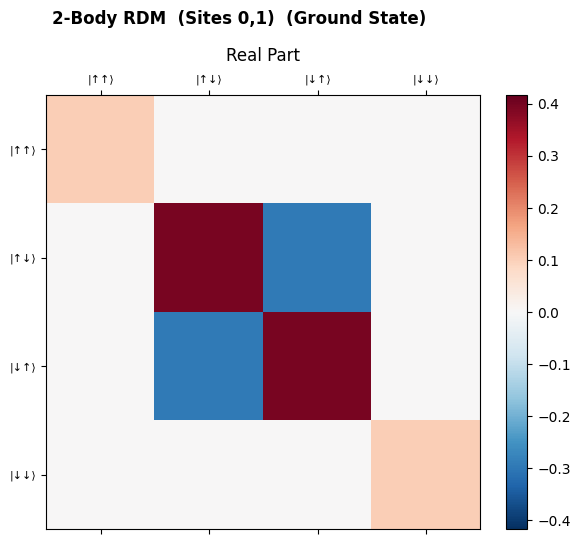

In [7]:
sites_2b = (0, 1)
fig = plot_rdm_heatmap(rdm_pure[sites_2b], sites_2b, title_suffix='(Ground State)')
plt.show()

## 6  GME analysis (n ≥ 3)

In [8]:
# Filter to 3-body RDMs
rdm_3b = {k: v for k, v in rdm_pure.items() if len(k) == 3}
gme_results = check_GME_for_all_rdms(rdm_3b, verbose=True)


  Subsystem sites : (0, 1, 2)
  Global purity   : 0.46262004
  → Mixed state: pure-state GME formula not applicable.

  Subsystem sites : (1, 2, 3)
  Global purity   : 0.46262004
  → Mixed state: pure-state GME formula not applicable.

  Subsystem sites : (2, 3, 0)
  Global purity   : 0.46262004
  → Mixed state: pure-state GME formula not applicable.

  Subsystem sites : (3, 0, 1)
  Global purity   : 0.46262004
  → Mixed state: pure-state GME formula not applicable.


In [9]:
# Collect C_GME values across all 3-body clusters
print('\nC_GME per 3-body cluster:')
for sites, cgme in gme_results.items():
    label = 'mixed' if cgme is None else (f'{cgme:.6f}' if cgme > 0 else 'no GME')
    print(f'  Sites {sites}  →  {label}')


C_GME per 3-body cluster:
  Sites (0, 1, 2)  →  mixed
  Sites (1, 2, 3)  →  mixed
  Sites (2, 3, 0)  →  mixed
  Sites (3, 0, 1)  →  mixed


## 7  C_GME lower bound via coherence witness

In [10]:
sites_3b = (0, 1, 2)
rho = rdm_pure[sites_3b]
C_upper = compute_C_GME_pure(rho, 3)
C_lower, I = Cgme_lower_bound(rho, 3)
print(f'C_GME upper (bipartition) = {C_upper:.8f}')
print(f'C_GME lower bound         = {C_lower:.8f}  (I = {I:.8f})')

C_GME upper (bipartition) = 0.94030936
C_GME lower bound         = 0.00000000  (I = -0.50000000)


## 8  Full pipeline with PDF output

In [ ]:
# Uncomment to generate PDFs
result = run_pure_analysis(
    L=4, t=1.0, U=4.0, mode='uniform',
    n_electrons=4, max_n_body=4,
    output_dir='../outputs', generate_pdf=True
)


  PURE RDM ANALYSIS PIPELINE
  L=4  t=1.0  U=4.0  mode=uniform  Ne=4
------------------------------------------------------------

[1/4] Diagonalising Hamiltonian …
      E₀ = -2.1027484835
      E₁ = -1.8064238518
      Gap Δ = 0.296325

[2/3] Computing RDMs (n = 1 … 4) …
  Computing 1-body RDMs (4 clusters) …
  Computing 2-body RDMs (4 clusters) …
  Computing 3-body RDMs (4 clusters) …
  Computing 4-body RDMs (4 clusters) …
      Done. Total RDMs computed: 16

[3/4] Running convex-roof analysis (4 mixed RDMs) …

  [Convex roof]  sites=(0,1,2)  n=3  γ=0.462620
    C_LB  (witness)     = 0.00000000
    C_num (convex roof) = 0.50351431   ← best estimate
    C_UB  (eigen)       = 0.71636717
    Bounds consistent   : True
    Status              : GME

  [Convex roof]  sites=(1,2,3)  n=3  γ=0.462620
    C_LB  (witness)     = 0.00000000
    C_num (convex roof) = 0.50351431   ← best estimate
    C_UB  (eigen)       = 0.71636717
    Bounds consistent   : True
    Status              : GME

 

: 